# Proyecto de Machine Learning: deserción académica y niveles de obesidad

Universidad de Lima · Ingeniería de Sistemas · Curso de Machine Learning

Este notebook implementa el **código** del proyecto para los dos datasets de UCI:

1. *Predict Students' Dropout and Academic Success* (id 697)
2. *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (id 544)

Flujo: carga → EDA y calidad de datos → partición train/test → pipeline (preprocesamiento + selección de features + modelo) → afinamiento con **Optuna** → comparativa final.

Las celdas de **Interpretación** quedan para que el grupo las complete con sus propias palabras.

In [1]:
# ==============================================================================
# APORTES POR INTEGRANTE (completar: el enunciado pide indicar lo realizado por cada uno)
#   - Fabrizio Ivan Armas Ramirez:            [completar]
#   - Antonio Alexander Sifuentes Linares:    [completar]
#   - Arce Mendoza Josué Fernando:            [completar]
#   - [Cuarto integrante, si aplica]:         [completar]
#
# USO DE HERRAMIENTAS DE IA (obligatorio según las reglas del proyecto)
#   Herramienta: Claude (Anthropic)
#   Prompt utilizado: [reemplazar por el prompt EXACTO que usaron; ejemplo:
#   "Implementar el código del proyecto: EDA, selección de features, afinamiento con
#    Optuna y comparativa de modelos para los datasets UCI 697 y 544, con métodos
#    distintos a los usados por los autores."]
#   El reporte NO fue generado con IA.
# ==============================================================================

In [2]:
import io, os, time, urllib.request, warnings, zipfile

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

# --- Configuración global ---------------------------------------------------------
SEED = 42
N_TRIALS = int(os.environ.get("N_TRIALS", 20))   # pruebas de Optuna por modelo (súbanlo si hay tiempo)
CV_FOLDS = 3                                       # folds de validación cruzada dentro de TRAIN
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)


def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga de datos
Si los CSV no están en `datos/`, se descargan de UCI.

In [3]:
URLS = {
    "dropout": "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip",
    "obesity": "https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition.zip",
}


def ruta_csv(nombre, carpeta="datos"):
    """Devuelve la ruta del CSV del dataset; lo descarga de UCI si no existe."""
    destino = os.path.join(carpeta, nombre)
    os.makedirs(destino, exist_ok=True)
    if not any(f.endswith(".csv") for f in os.listdir(destino)):
        contenido = urllib.request.urlopen(URLS[nombre]).read()
        zipfile.ZipFile(io.BytesIO(contenido)).extractall(destino)
    return os.path.join(destino, next(f for f in os.listdir(destino) if f.endswith(".csv")))


df_d = pd.read_csv(ruta_csv("dropout"), sep=";")
df_d.columns = df_d.columns.str.strip()          # una columna trae un tabulador en el nombre
df_o = pd.read_csv(ruta_csv("obesity"))
print("Dropout:", df_d.shape, "| Obesity:", df_o.shape)

Dropout: (4424, 37) | Obesity: (2111, 17)


## 2. Dataset 1: Dropout / Academic Success

### 2.1 EDA y calidad de datos

Dimensiones: (4424, 37)
Nulos totales: 0 | Duplicados: 0
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9


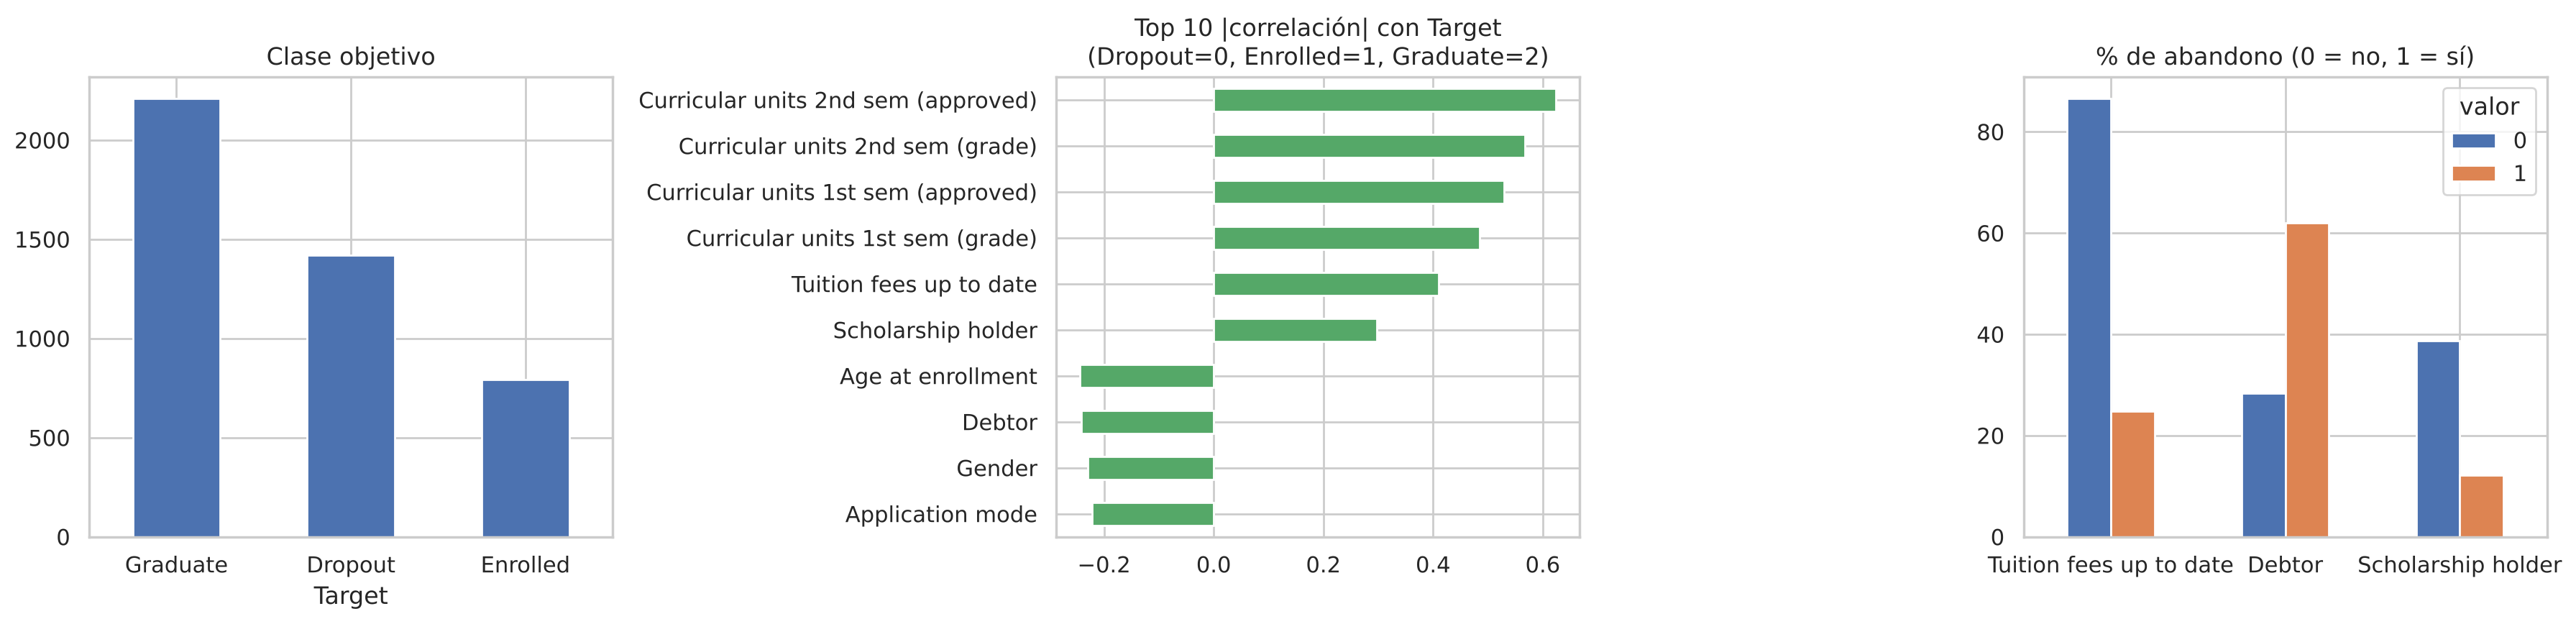

In [4]:
MAPA_TARGET = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}

print("Dimensiones:", df_d.shape)
print("Nulos totales:", int(df_d.isna().sum().sum()), "| Duplicados:", int(df_d.duplicated().sum()))
dist = df_d["Target"].value_counts()
print((dist / len(df_d) * 100).round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
dist.plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Clase objetivo")

corr = df_d.drop(columns="Target").assign(y=df_d["Target"].map(MAPA_TARGET)).corr()["y"].drop("y")
corr.reindex(corr.abs().sort_values(ascending=False).index)[:10][::-1].plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("Top 10 |correlación| con Target\n(Dropout=0, Enrolled=1, Graduate=2)")

claves = ["Tuition fees up to date", "Debtor", "Scholarship holder"]
tasas = pd.DataFrame({c: df_d.groupby(c)["Target"].apply(lambda s: (s == "Dropout").mean() * 100) for c in claves}).T
tasas.plot.bar(ax=ax[2], rot=0)
ax[2].set_title("% de abandono (0 = no, 1 = sí)")
ax[2].legend(title="valor")
guardar_fig("eda_dropout")

In [5]:
# Revisión de posibles problemas ocultos (no hay NaN, pero sí valores a vigilar)
cols_num = ["Age at enrollment", "Admission grade", "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
print(df_d[cols_num].describe().T.round(2))
print("\n% con 0 unidades aprobadas en 2do semestre:",
      round((df_d["Curricular units 2nd sem (approved)"] == 0).mean() * 100, 1))

# Multicolinealidad: pares de variables con |r| > 0.7
c = df_d.drop(columns="Target").corr().abs()
pares = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
print("\nPares con |r| > 0.7:")
print(pares[pares > 0.7].sort_values(ascending=False).round(3).to_string())

                                   count    mean    std   min     25%     50%  \
Age at enrollment                 4424.0   23.27   7.59  17.0   19.00   20.00   
Admission grade                   4424.0  126.98  14.48  95.0  117.90  126.10   
Curricular units 1st sem (grade)  4424.0   10.64   4.84   0.0   11.00   12.29   
Curricular units 2nd sem (grade)  4424.0   10.23   5.21   0.0   10.75   12.20   

                                     75%     max  
Age at enrollment                  25.00   70.00  
Admission grade                   134.80  190.00  
Curricular units 1st sem (grade)   13.40   18.88  
Curricular units 2nd sem (grade)   13.33   18.57  

% con 0 unidades aprobadas en 2do semestre: 19.7

Pares con |r| > 0.7:
Curricular units 1st sem (credited)     Curricular units 2nd sem (credited)       0.945
Curricular units 1st sem (enrolled)     Curricular units 2nd sem (enrolled)       0.943
Mother's occupation                     Father's occupation                       0.910
Cur

**Interpretación (completar por el grupo):** ¿qué dice el desbalance de clases sobre la métrica a usar? ¿Qué variables parecen más relacionadas con el abandono? ¿Qué implica la multicolinealidad?

## 3. Dataset 2: Obesity Levels

### 3.1 EDA y calidad de datos

Dimensiones: (2111, 17)
Nulos totales: 0 | Duplicados: 24

% de valores NO enteros:
FCVC    39.1
NCP     30.3
CH2O    61.1
FAF     57.2
TUE     54.6


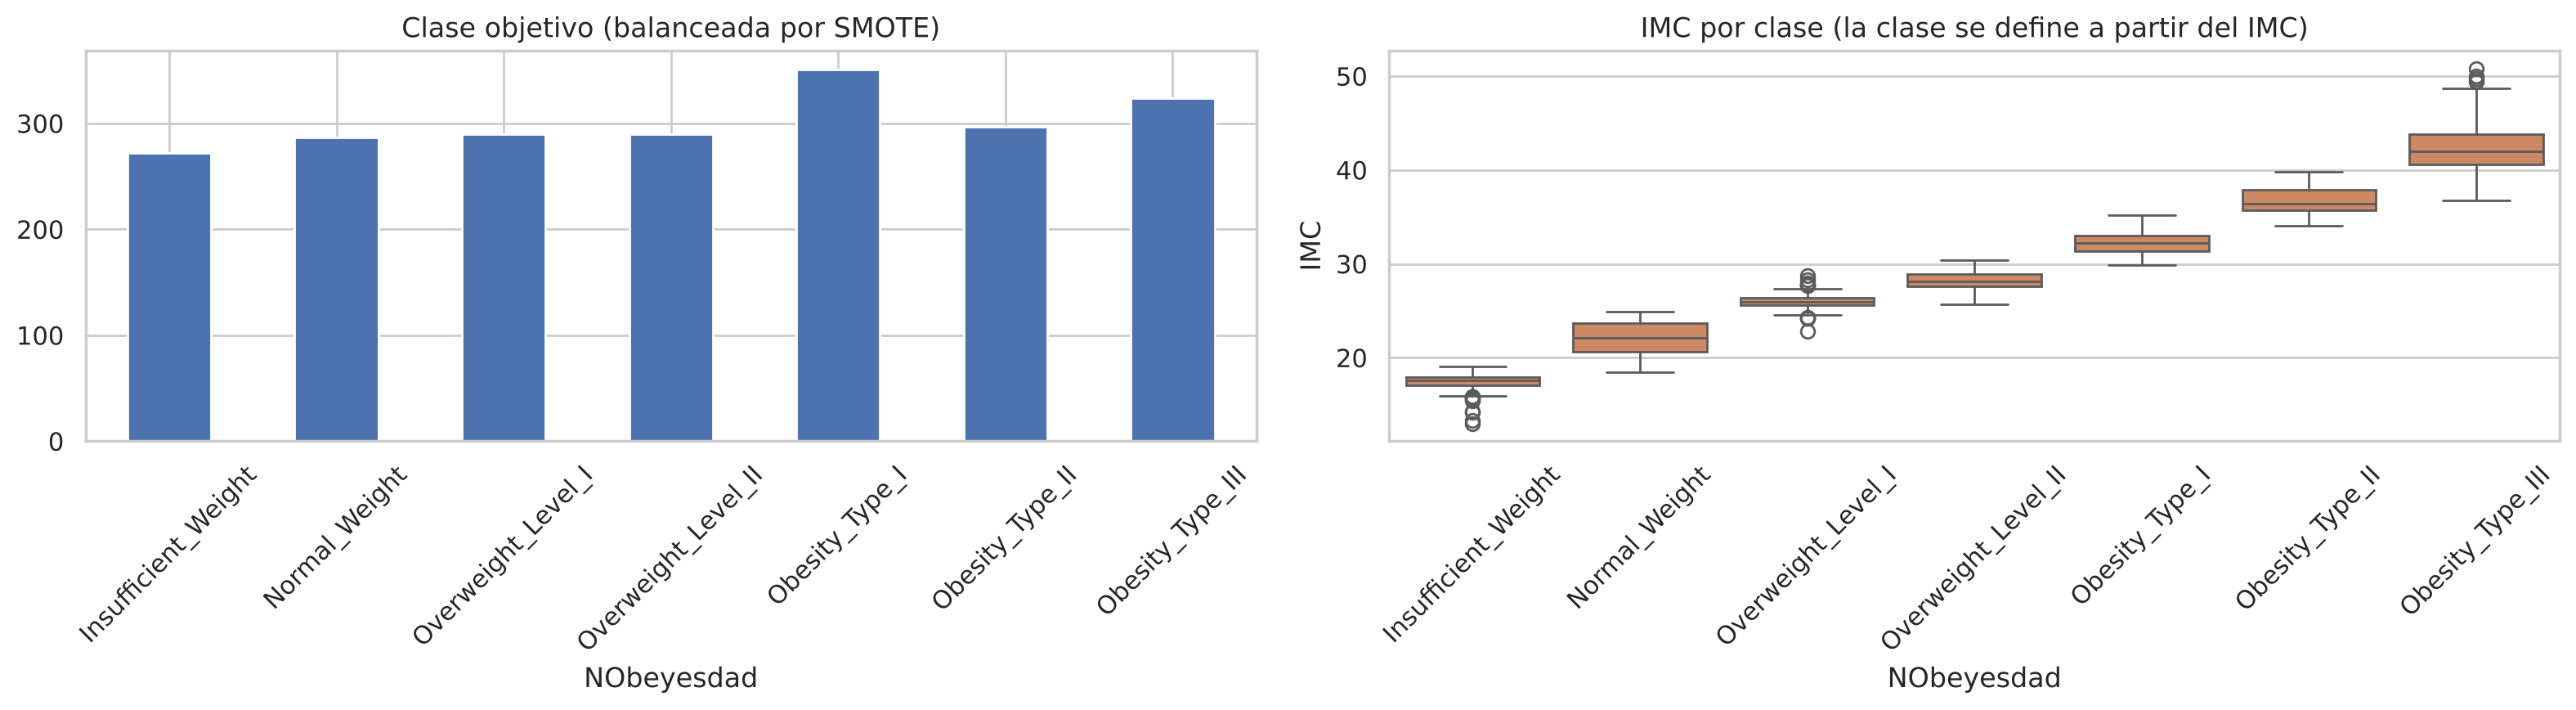

Tras eliminar duplicados: (2087, 17)


In [6]:
ORDEN_OBESIDAD = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                  "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

print("Dimensiones:", df_o.shape)
print("Nulos totales:", int(df_o.isna().sum().sum()), "| Duplicados:", int(df_o.duplicated().sum()))

# Evidencia de datos sintéticos (SMOTE): variables ordinales de encuesta con decimales
ordinales = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
print("\n% de valores NO enteros:")
print(((df_o[ordinales] != df_o[ordinales].round()).mean() * 100).round(1).to_string())

df_o["IMC"] = df_o["Weight"] / df_o["Height"] ** 2   # solo para análisis; NO es feature del modelo

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
df_o["NObeyesdad"].value_counts().reindex(ORDEN_OBESIDAD).plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Clase objetivo (balanceada por SMOTE)")
ax[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=df_o, x="NObeyesdad", y="IMC", order=ORDEN_OBESIDAD, ax=ax[1], color="#DD8452")
ax[1].set_title("IMC por clase (la clase se define a partir del IMC)")
ax[1].tick_params(axis="x", rotation=45)
guardar_fig("eda_obesity")

# Decisión: eliminar duplicados exactos antes de particionar
df_o = df_o.drop(columns="IMC").drop_duplicates().reset_index(drop=True)
print("Tras eliminar duplicados:", df_o.shape)

**Interpretación (completar por el grupo):** ¿qué riesgo trae que `Height` y `Weight` definan la clase (fuga de información)? ¿Qué implica que 77 % de los datos sea sintético?

## 4. Infraestructura de modelado

Decisiones de diseño:

- **Train / Test**: 80 % / 20 % estratificado. El test se usa **una sola vez** al final.
- **Validación**: validación cruzada estratificada de 3 folds **dentro de train**, para que Optuna elija hiperparámetros sin tocar el test.
- **Pipeline completo en cada fold** (one-hot + escalado + selección de features + modelo), así el preprocesamiento se ajusta solo con los datos de entrenamiento de cada fold y no hay fuga de información.
- **Selección de features**: `SelectKBest(f_classif)`, con `k` como hiperparámetro que Optuna también optimiza.
- **Métrica de optimización**: F1 macro (trata igual a todas las clases, útil con desbalance).
- **Métodos propuestos** (distintos a los usados por los autores) vs. **referencia** (Random Forest, usado por los autores en ambos datasets).

In [7]:
def construir_prep(X, cat_cols):
    """One-hot para categóricas (agrupa categorías raras) y estandarización para numéricas."""
    num_cols = [c for c in X.columns if c not in cat_cols]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=10), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])


def modelos_base(balanced):
    """Modelos con hiperparámetros por defecto (punto de comparación 'sin afinar')."""
    cw = "balanced" if balanced else None
    return {
        "logreg": LogisticRegression(max_iter=2000, class_weight=cw),
        "knn": KNeighborsClassifier(),
        "svm": SVC(class_weight=cw, random_state=SEED),
        "mlp": MLPClassifier(max_iter=300, early_stopping=True, random_state=SEED),
        "extratrees": ExtraTreesClassifier(n_estimators=200, class_weight=cw, random_state=SEED, n_jobs=-1),
        "hgb": HistGradientBoostingClassifier(class_weight=cw, random_state=SEED),
        "rf": RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEED, n_jobs=-1),
    }


def sugerir_modelo(nombre, trial, balanced):
    """Espacio de búsqueda de Optuna para cada algoritmo."""
    cw = "balanced" if balanced else None
    if nombre == "logreg":
        return LogisticRegression(C=trial.suggest_float("C", 1e-3, 1e2, log=True), max_iter=2000, class_weight=cw)
    if nombre == "knn":
        return KNeighborsClassifier(n_neighbors=trial.suggest_int("n_neighbors", 3, 30),
                                    weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
                                    p=trial.suggest_int("p", 1, 2))
    if nombre == "svm":
        return SVC(C=trial.suggest_float("C", 1e-2, 1e3, log=True),
                   gamma=trial.suggest_float("gamma", 1e-4, 1e0, log=True),
                   class_weight=cw, random_state=SEED)
    if nombre == "mlp":
        capas = trial.suggest_int("n_capas", 1, 3)
        neuronas = tuple(trial.suggest_int(f"neuronas_{i}", 16, 128, log=True) for i in range(capas))
        return MLPClassifier(hidden_layer_sizes=neuronas,
                             activation=trial.suggest_categorical("activation", ["relu", "tanh"]),
                             alpha=trial.suggest_float("alpha", 1e-5, 1e-1, log=True),
                             learning_rate_init=trial.suggest_float("lr", 1e-4, 1e-2, log=True),
                             batch_size=trial.suggest_categorical("batch", [32, 64, 128]),
                             max_iter=300, early_stopping=True, n_iter_no_change=10, random_state=SEED)
    if nombre == "extratrees":
        return ExtraTreesClassifier(n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
                                    max_depth=trial.suggest_int("max_depth", 5, 30),
                                    min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
                                    max_features=trial.suggest_categorical("max_features", ["sqrt", "log2"]),
                                    class_weight=cw, random_state=SEED, n_jobs=-1)
    if nombre == "hgb":
        return HistGradientBoostingClassifier(learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                                              max_depth=trial.suggest_int("max_depth", 3, 10),
                                              max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 64),
                                              l2_regularization=trial.suggest_float("l2", 1e-4, 10, log=True),
                                              max_iter=trial.suggest_int("max_iter", 100, 300, step=50),
                                              class_weight=cw, random_state=SEED)
    raise ValueError(nombre)


def pipeline_afinable(nombre, trial, X, cat_cols, balanced, n_feat):
    """Pipeline cuyos hiperparámetros (incluido k de selección de features) salen del trial."""
    k = trial.suggest_int("k_features", max(5, n_feat // 5), n_feat)
    return Pipeline([("prep", construir_prep(X, cat_cols)),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("model", sugerir_modelo(nombre, trial, balanced))])


def pipeline_base(nombre, X, cat_cols, balanced):
    return Pipeline([("prep", construir_prep(X, cat_cols)),
                     ("select", SelectKBest(f_classif, k="all")),
                     ("model", modelos_base(balanced)[nombre])])


def tunar(nombre, X_tr, y_tr, cat_cols, balanced, n_trials):
    """Optuna (TPE) maximiza el F1 macro medio en validación cruzada sobre TRAIN."""
    n_feat = construir_prep(X_tr, cat_cols).fit_transform(X_tr).shape[1]
    cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)

    def objetivo(trial):
        pipe = pipeline_afinable(nombre, trial, X_tr, cat_cols, balanced, n_feat)
        return cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro").mean()

    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=n_trials)
    mejor = pipeline_afinable(nombre, optuna.trial.FixedTrial(estudio.best_params), X_tr, cat_cols, balanced, n_feat)
    return estudio, mejor


def evaluar(pipe, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    return {"test_acc": accuracy_score(y_te, pred), "test_f1_macro": f1_score(y_te, pred, average="macro"),
            "seg_entrenamiento": round(time.time() - t0, 1)}, pred

In [8]:
def correr_experimento(X, y, cat_cols, propuestos, referencia, balanced, dataset, escenario, n_trials=N_TRIALS):
    """Entrena referencia + propuestos (base y afinados con Optuna) y evalúa en test."""
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
    filas, pipes, estudios = [], {}, {}

    def registrar(nombre, version, pipe, cv_f1=np.nan):
        met, pred = evaluar(pipe, X_tr, y_tr, X_te, y_te)
        filas.append({"dataset": dataset, "escenario": escenario, "modelo": nombre, "version": version,
                      "cv_f1_macro": cv_f1, **met})
        pipes[(nombre, version)] = (pipe, pred)

    for nombre in referencia:
        registrar(nombre, "referencia (autores)", pipeline_base(nombre, X, cat_cols, balanced))
    for nombre in propuestos:
        registrar(nombre, "propuesto base", pipeline_base(nombre, X, cat_cols, balanced))
        t0 = time.time()
        estudio, mejor = tunar(nombre, X_tr, y_tr, cat_cols, balanced, n_trials)
        estudios[nombre] = estudio
        registrar(nombre, "propuesto afinado", mejor, cv_f1=estudio.best_value)
        print(f"[{dataset} | {escenario}] {nombre}: CV F1={estudio.best_value:.3f} "
              f"({n_trials} pruebas, {time.time() - t0:.0f}s) mejores params: {estudio.best_params}")

    return pd.DataFrame(filas), pipes, estudios, (X_tr, X_te, y_tr, y_te)

## 5. Experimento 1: Dropout

- **Referencia (autores):** Random Forest.
- **Propuestos:** SVM (kernel RBF), red neuronal MLP, KNN y regresión logística. SVM y MLP son los métodos principales; MLP además cumple la estrategia de *afinamiento de redes neuronales con Optuna*.
- Las columnas categóricas nominales guardadas como enteros se tratan con one-hot.
- Se usa `class_weight="balanced"` donde el modelo lo permite (KNN y MLP no lo soportan; ahí se confía en F1 macro).

In [9]:
NOMINALES_DROPOUT = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
                     "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

X_d = df_d.drop(columns="Target")
y_d = df_d["Target"]

res_d, pipes_d, estudios_d, split_d = correr_experimento(
    X_d, y_d, NOMINALES_DROPOUT,
    propuestos=["logreg", "knn", "svm", "mlp"], referencia=["rf"],
    balanced=True, dataset="Dropout", escenario="todas las variables")
res_d.round(4)

[Dropout | todas las variables] logreg: CV F1=0.717 (20 pruebas, 5s) mejores params: {'k_features': 58, 'C': 0.4205156450913872}


[Dropout | todas las variables] knn: CV F1=0.660 (20 pruebas, 5s) mejores params: {'k_features': 36, 'n_neighbors': 4, 'weights': 'uniform', 'p': 1}


[Dropout | todas las variables] svm: CV F1=0.721 (20 pruebas, 30s) mejores params: {'k_features': 126, 'C': 35.662919437347526, 'gamma': 0.0027768303035028336}


[Dropout | todas las variables] mlp: CV F1=0.719 (20 pruebas, 24s) mejores params: {'k_features': 66, 'n_capas': 3, 'neuronas_0': 73, 'neuronas_1': 55, 'neuronas_2': 22, 'activation': 'relu', 'alpha': 0.029154431891537533, 'lr': 0.0015930522616241021, 'batch': 128}


,dataset,escenario,modelo,version,cv_f1_macro,test_acc,test_f1_macro,seg_entrenamiento
0,Dropout,todas las variables,rf,referencia (autores),NaN,0.7638,0.7121,1.2
1,Dropout,todas las variables,logreg,propuesto base,NaN,0.7209,0.6839,0.2
2,Dropout,todas las variables,logreg,propuesto afinado,0.7165,0.7333,0.6971,0.1
3,Dropout,todas las variables,knn,propuesto base,NaN,0.7028,0.6196,0.1
4,Dropout,todas las variables,knn,propuesto afinado,0.6596,0.7175,0.6354,0.1
5,Dropout,todas las variables,svm,propuesto base,NaN,0.7322,0.6936,0.9
6,Dropout,todas las variables,svm,propuesto afinado,0.7214,0.7345,0.6960,0.9
7,Dropout,todas las variables,mlp,propuesto base,NaN,0.7616,0.6894,0.7
8,Dropout,todas las variables,mlp,propuesto afinado,0.7193,0.7548,0.6858,0.3


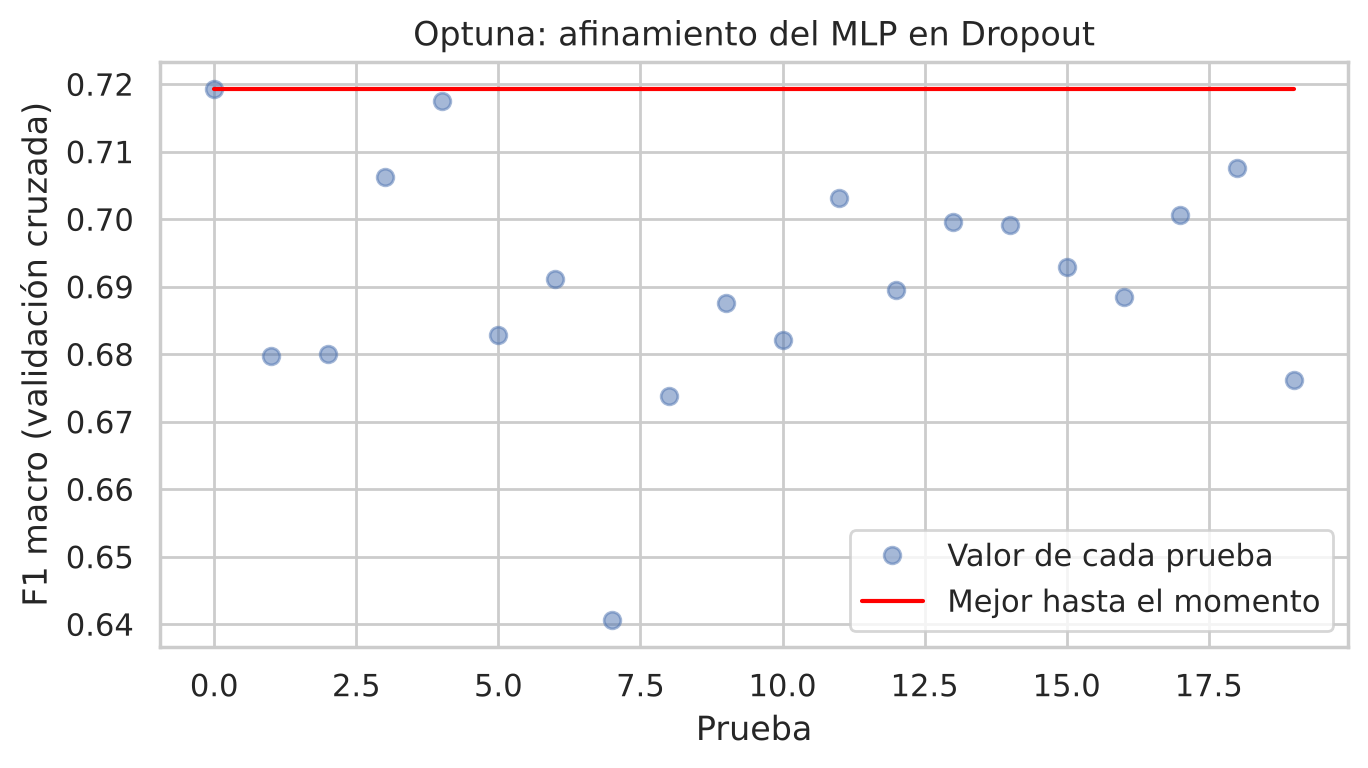

In [10]:
# Historia de optimización de Optuna para la red neuronal (MLP)
h = estudios_d["mlp"].trials_dataframe()
plt.figure(figsize=(7, 4))
plt.plot(h["number"], h["value"], "o", alpha=0.5, label="Valor de cada prueba")
plt.plot(h["number"], h["value"].cummax(), "-", color="red", label="Mejor hasta el momento")
plt.xlabel("Prueba"); plt.ylabel("F1 macro (validación cruzada)")
plt.title("Optuna: afinamiento del MLP en Dropout"); plt.legend()
guardar_fig("optuna_mlp_dropout")

**Interpretación (completar por el grupo):** ¿el afinamiento mejoró respecto a los hiperparámetros por defecto? ¿La selección de features cambió algo? ¿Qué modelo propuesto se acerca más a la referencia?

## 6. Experimento 2: Obesity

- **Referencia (autores):** Random Forest.
- **Propuestos:** Gradient Boosting (`HistGradientBoosting`), Extra Trees, KNN y regresión logística multinomial.
- Se corre en **dos escenarios**: con todas las variables y **sin `Height` ni `Weight`**, porque estas dos permiten calcular el IMC que define la clase.

In [11]:
CATEGORICAS_OBESITY = [c for c in df_o.columns
                       if not pd.api.types.is_numeric_dtype(df_o[c]) and c != "NObeyesdad"]
print("Categóricas:", CATEGORICAS_OBESITY)

y_o = df_o["NObeyesdad"]
X_o_todas = df_o.drop(columns="NObeyesdad")
X_o_sin_hw = X_o_todas.drop(columns=["Height", "Weight"])
PROP_OBESITY = ["logreg", "knn", "extratrees", "hgb"]

res_o1, pipes_o1, estudios_o1, split_o1 = correr_experimento(
    X_o_todas, y_o, CATEGORICAS_OBESITY, PROP_OBESITY, ["rf"],
    balanced=False, dataset="Obesity", escenario="con Height y Weight")
res_o1.round(4)

Categóricas: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']


[Obesity | con Height y Weight] logreg: CV F1=0.960 (20 pruebas, 5s) mejores params: {'k_features': 14, 'C': 82.62810495772486}


[Obesity | con Height y Weight] knn: CV F1=0.856 (20 pruebas, 3s) mejores params: {'k_features': 17, 'n_neighbors': 3, 'weights': 'distance', 'p': 1}


[Obesity | con Height y Weight] extratrees: CV F1=0.900 (20 pruebas, 20s) mejores params: {'k_features': 20, 'n_estimators': 150, 'max_depth': 22, 'min_samples_leaf': 1, 'max_features': 'log2'}


[Obesity | con Height y Weight] hgb: CV F1=0.965 (20 pruebas, 48s) mejores params: {'k_features': 15, 'learning_rate': 0.262516606324193, 'max_depth': 8, 'max_leaf_nodes': 42, 'l2': 0.0006026889128682511, 'max_iter': 100}


,dataset,escenario,modelo,version,cv_f1_macro,test_acc,test_f1_macro,seg_entrenamiento
0,Obesity,con Height y Weight,rf,referencia (autores),NaN,0.9402,0.9388,0.8
1,Obesity,con Height y Weight,logreg,propuesto base,NaN,0.8971,0.8928,0.1
2,Obesity,con Height y Weight,logreg,propuesto afinado,0.9603,0.9737,0.9731,0.1
3,Obesity,con Height y Weight,knn,propuesto base,NaN,0.8278,0.8062,0.0
4,Obesity,con Height y Weight,knn,propuesto afinado,0.8555,0.8876,0.8826,0.0
5,Obesity,con Height y Weight,extratrees,propuesto base,NaN,0.9115,0.9096,0.4
6,Obesity,con Height y Weight,extratrees,propuesto afinado,0.9000,0.9163,0.9142,0.3
7,Obesity,con Height y Weight,hgb,propuesto base,NaN,0.9761,0.9756,1.2
8,Obesity,con Height y Weight,hgb,propuesto afinado,0.9651,0.9737,0.9728,0.6


In [12]:
res_o2, pipes_o2, estudios_o2, split_o2 = correr_experimento(
    X_o_sin_hw, y_o, CATEGORICAS_OBESITY, PROP_OBESITY, ["rf"],
    balanced=False, dataset="Obesity", escenario="sin Height ni Weight")
res_o2.round(4)

[Obesity | sin Height ni Weight] logreg: CV F1=0.572 (20 pruebas, 6s) mejores params: {'k_features': 22, 'C': 15.667105633536632}


[Obesity | sin Height ni Weight] knn: CV F1=0.781 (20 pruebas, 2s) mejores params: {'k_features': 28, 'n_neighbors': 3, 'weights': 'distance', 'p': 1}


[Obesity | sin Height ni Weight] extratrees: CV F1=0.805 (20 pruebas, 22s) mejores params: {'k_features': 24, 'n_estimators': 100, 'max_depth': 22, 'min_samples_leaf': 1, 'max_features': 'log2'}


[Obesity | sin Height ni Weight] hgb: CV F1=0.821 (20 pruebas, 71s) mejores params: {'k_features': 25, 'learning_rate': 0.10580101351602858, 'max_depth': 6, 'max_leaf_nodes': 46, 'l2': 0.007787814947631603, 'max_iter': 200}


,dataset,escenario,modelo,version,cv_f1_macro,test_acc,test_f1_macro,seg_entrenamiento
0,Obesity,sin Height ni Weight,rf,referencia (autores),NaN,0.8397,0.8357,0.8
1,Obesity,sin Height ni Weight,logreg,propuesto base,NaN,0.6268,0.5866,0.1
2,Obesity,sin Height ni Weight,logreg,propuesto afinado,0.5725,0.6364,0.5964,0.2
3,Obesity,sin Height ni Weight,knn,propuesto base,NaN,0.7512,0.7243,0.0
4,Obesity,sin Height ni Weight,knn,propuesto afinado,0.7806,0.8062,0.7986,0.0
5,Obesity,sin Height ni Weight,extratrees,propuesto base,NaN,0.8445,0.8399,0.4
6,Obesity,sin Height ni Weight,extratrees,propuesto afinado,0.8055,0.8301,0.8248,0.2
7,Obesity,sin Height ni Weight,hgb,propuesto base,NaN,0.8469,0.8438,1.4
8,Obesity,sin Height ni Weight,hgb,propuesto afinado,0.8208,0.8373,0.8325,1.7


**Interpretación (completar por el grupo):** compara ambos escenarios. ¿Qué pasa con el desempeño cuando se quitan peso y altura? ¿Qué te dice eso sobre lo que realmente aportan los hábitos alimenticios y la condición física? Recuerda que 77 % del dataset es sintético.

## 7. Comparativa final

dataset            escenario     modelo              version  cv_f1_macro  test_acc  test_f1_macro  seg_entrenamiento
Dropout  todas las variables         rf referencia (autores)          NaN    0.7638         0.7121                1.2
Dropout  todas las variables     logreg    propuesto afinado       0.7165    0.7333         0.6971                0.1
Dropout  todas las variables        svm    propuesto afinado       0.7214    0.7345         0.6960                0.9
Dropout  todas las variables        svm       propuesto base          NaN    0.7322         0.6936                0.9
Dropout  todas las variables        mlp       propuesto base          NaN    0.7616         0.6894                0.7
Dropout  todas las variables        mlp    propuesto afinado       0.7193    0.7548         0.6858                0.3
Dropout  todas las variables     logreg       propuesto base          NaN    0.7209         0.6839                0.2
Dropout  todas las variables        knn    propuesto afi

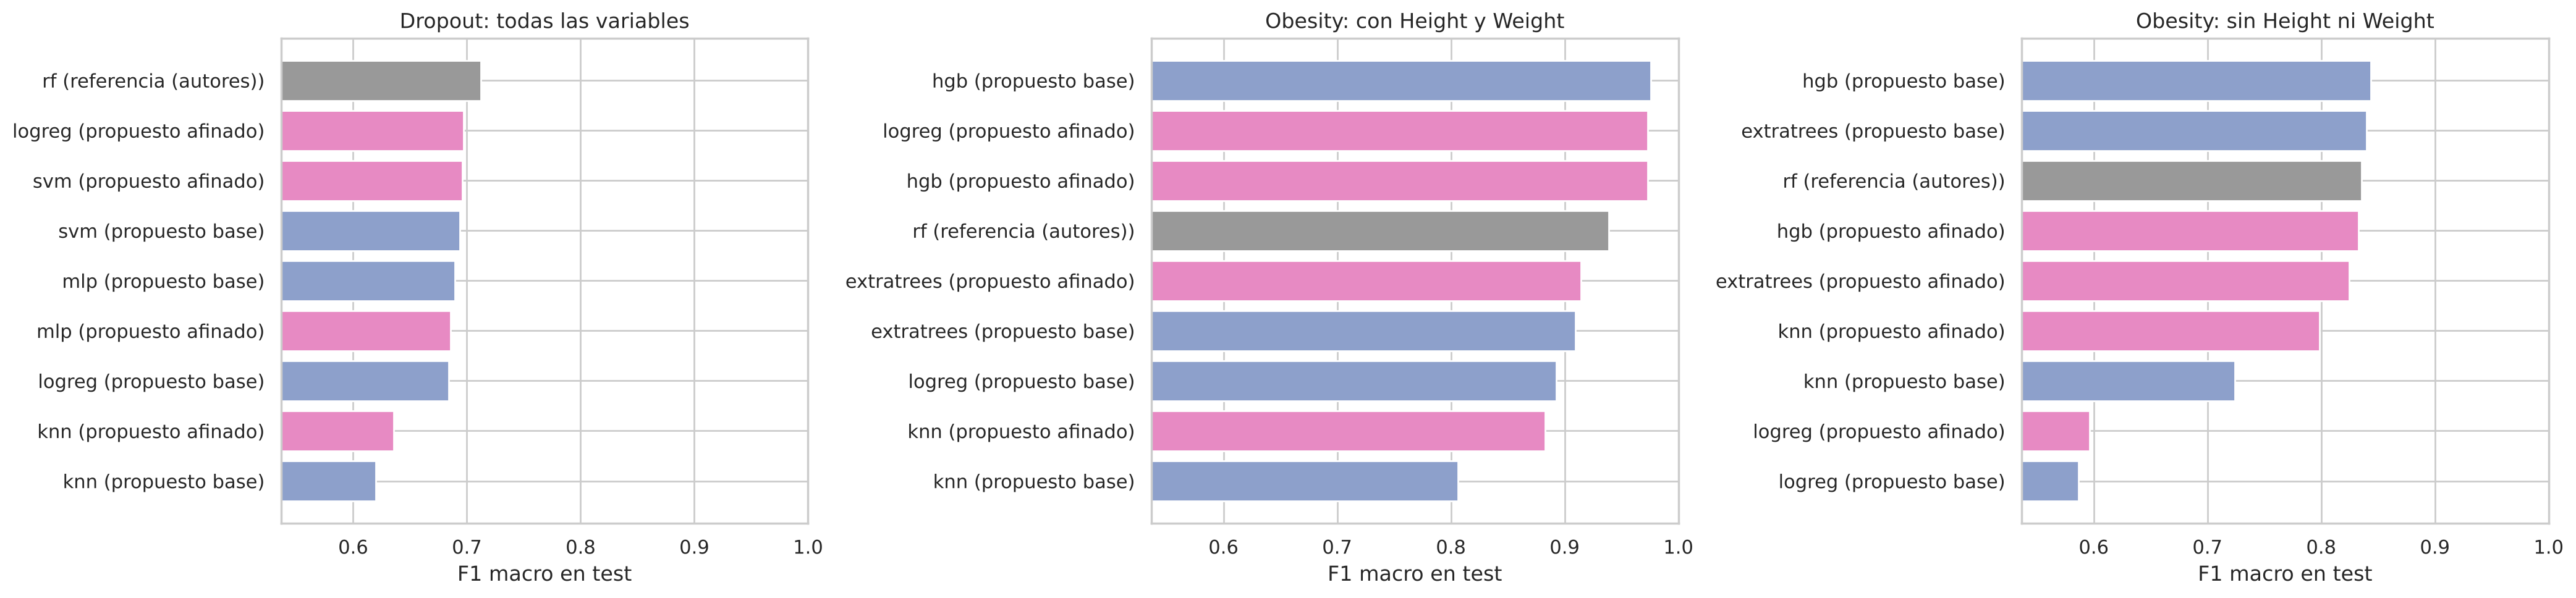

In [13]:
resultados = pd.concat([res_d, res_o1, res_o2], ignore_index=True)
resultados.to_csv("resultados/comparativa_modelos.csv", index=False)
pd.set_option("display.width", 200)
print(resultados.sort_values(["dataset", "escenario", "test_f1_macro"], ascending=[True, True, False])
      .round(4).to_string(index=False))

grupos = resultados.groupby(["dataset", "escenario"], sort=False)
fig, axes = plt.subplots(1, grupos.ngroups, figsize=(7 * grupos.ngroups, 5), sharex=True)
for ax, ((ds, esc), g) in zip(np.atleast_1d(axes), grupos):
    g = g.assign(etiqueta=g["modelo"] + " (" + g["version"] + ")").sort_values("test_f1_macro")
    colores = g["version"].map({"referencia (autores)": "#999999", "propuesto base": "#8DA0CB", "propuesto afinado": "#E78AC3"})
    ax.barh(g["etiqueta"], g["test_f1_macro"], color=colores)
    ax.set_title(f"{ds}: {esc}"); ax.set_xlabel("F1 macro en test")
    ax.set_xlim(max(0, g["test_f1_macro"].min() - 0.05), 1.0)
guardar_fig("comparativa_modelos")


=== Dropout: todas las variables | logreg ===
              precision    recall  f1-score   support

     Dropout      0.839     0.680     0.751       284
    Enrolled      0.419     0.654     0.511       159
    Graduate      0.865     0.796     0.829       442

    accuracy                          0.733       885
   macro avg      0.708     0.710     0.697       885
weighted avg      0.777     0.733     0.747       885

Features usadas tras SelectKBest: 58 de 132

=== Obesity: con Height y Weight | logreg ===
                     precision    recall  f1-score   support

Insufficient_Weight      1.000     1.000     1.000        53
      Normal_Weight      1.000     1.000     1.000        57
     Obesity_Type_I      1.000     0.971     0.986        70
    Obesity_Type_II      0.952     1.000     0.976        60
   Obesity_Type_III      1.000     0.985     0.992        65
 Overweight_Level_I      0.943     0.909     0.926        55
Overweight_Level_II      0.917     0.948     0.932   

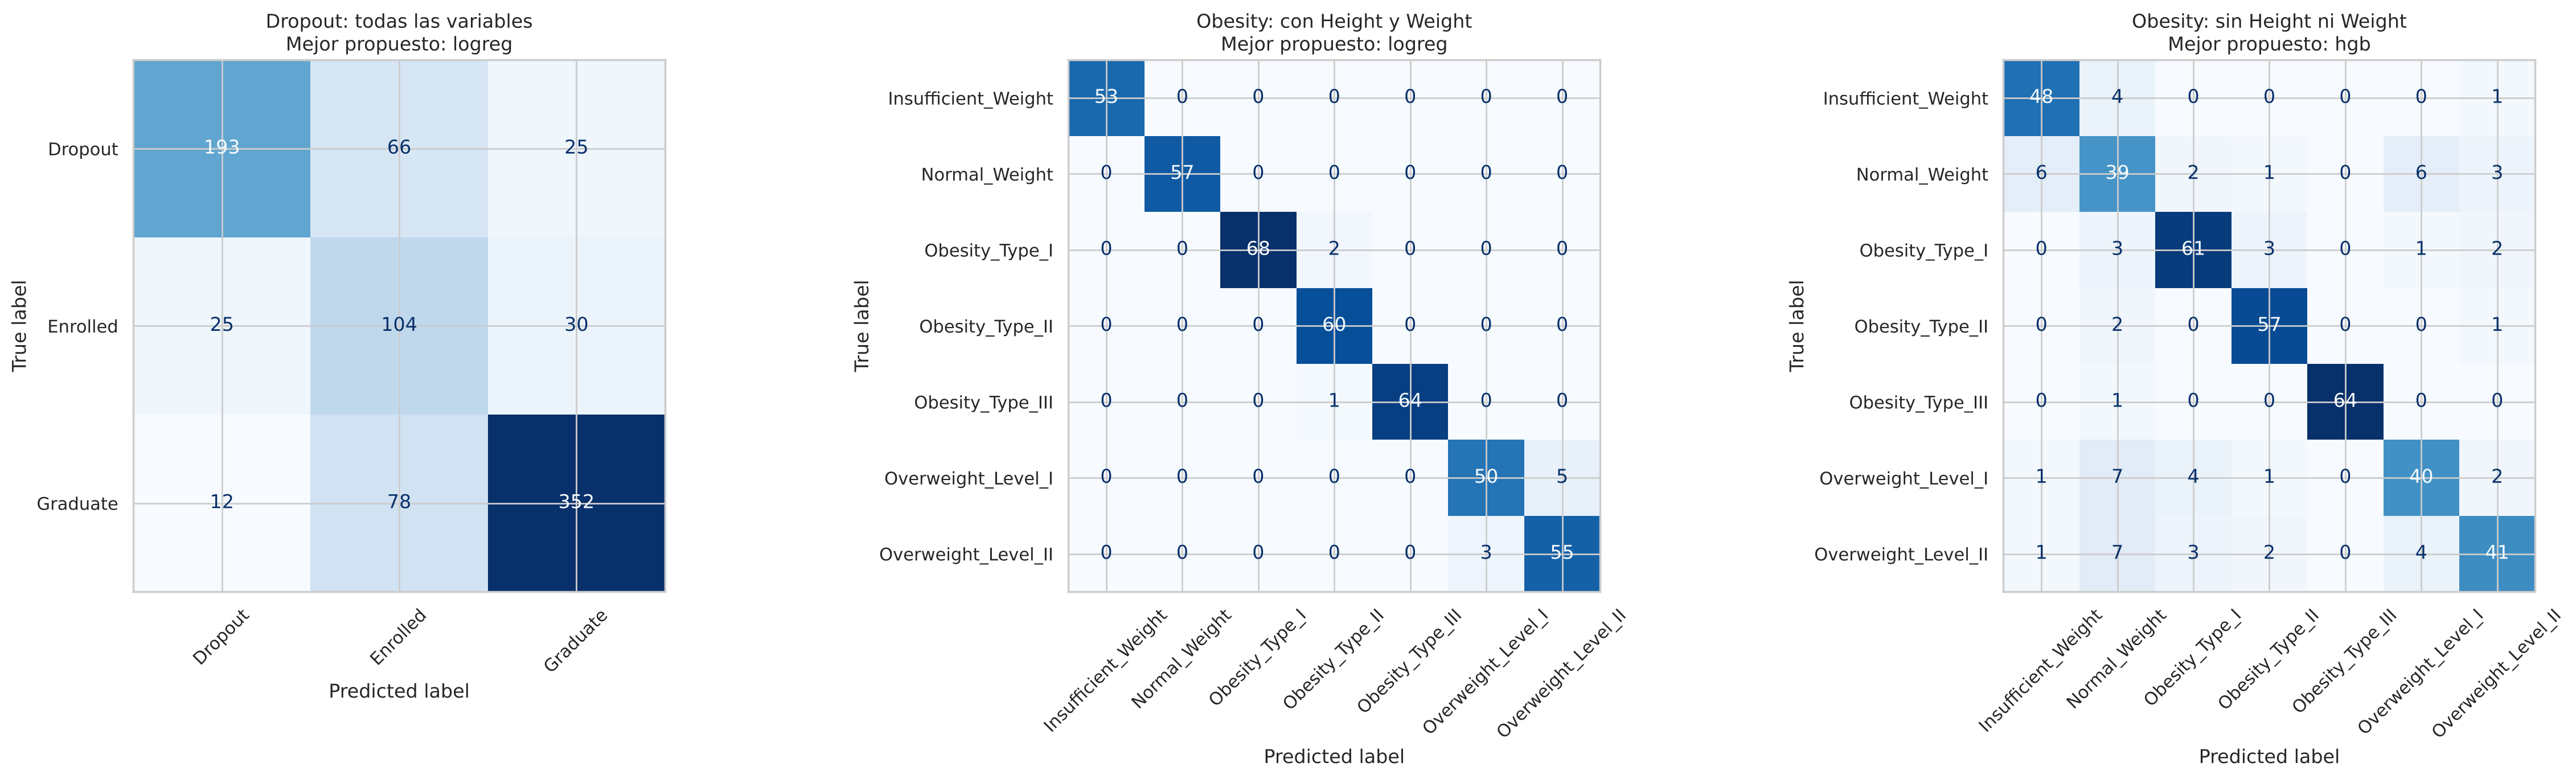

In [14]:
# Mejor modelo propuesto (afinado) por experimento: matriz de confusión y reporte
experimentos = [("Dropout: todas las variables", res_d, pipes_d, split_d),
                ("Obesity: con Height y Weight", res_o1, pipes_o1, split_o1),
                ("Obesity: sin Height ni Weight", res_o2, pipes_o2, split_o2)]

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (titulo, res, pipes, (X_tr, X_te, y_tr, y_te)) in zip(axes, experimentos):
    afinados = res[res["version"] == "propuesto afinado"]
    mejor = afinados.loc[afinados["test_f1_macro"].idxmax(), "modelo"]
    pipe, pred = pipes[(mejor, "propuesto afinado")]
    ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(f"{titulo}\nMejor propuesto: {mejor}")
    print(f"\n=== {titulo} | {mejor} ===")
    print(classification_report(y_te, pred, digits=3))
    seleccion = pipe.named_steps["select"].get_support()
    print(f"Features usadas tras SelectKBest: {int(seleccion.sum())} de {len(seleccion)}")
guardar_fig("matrices_confusion")

**Interpretación (completar por el grupo):** ¿qué modelo propuesto fue el mejor en cada dataset y por qué crees que ocurrió? ¿Superó a la referencia de los autores? ¿Qué clases se confunden más?